# SL-PINN for the 2D-2V Vlasov-Poisson system

We solve the Vlasov-Poisson equations in four-dimensional phase space
$z = (x, y, v_x, v_y)$ by learning the inverse characteristic flow map
$\Psi_\theta(t, z) \to z_0$ and reconstructing the distribution as
$f = f_0(\Psi_\theta)$. The electrostatic field is obtained from a spectral
Poisson solve on an Eulerian grid.

This notebook trains the map, compares it against a high-resolution spectral
semi-Lagrangian reference, and reports accuracy, conservation, runtime, and the
reconstructed characteristics. All functions are in `slpinn_2d2v.py`.

The map is parameterised in one of three ways, selected by `MODE` below:

- `symplectic` — volume-preserving coupling flow, $\det \nabla\Psi = 1$ exactly;
- `normalizing` — affine coupling flow, mass conserved through the
  change-of-variables reconstruction $f = f_0(\Psi)\,|\det \nabla\Psi|$;
- `soft` — unconstrained network with a soft penalty $(\det\nabla\Psi - 1)^2$.

Run the notebook once per mode; the conservation section collects whichever
modes have been run into a single comparison.

In [ ]:
import json
import time
from pathlib import Path

import matplotlib
try:
    get_ipython  # noqa: F821
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
import os


GPU = os.environ.get("SLPINN_GPU")
if GPU is None:
    try:
        import subprocess
        q = subprocess.run(["nvidia-smi", "--query-gpu=index,memory.used,memory.total",
                            "--format=csv,noheader,nounits"],
                           capture_output=True, text=True, timeout=10).stdout
        free = [(int(t) - int(u), i) for i, u, t in
                (ln.split(", ") for ln in q.strip().splitlines())]
        GPU = str(max(free)[1])
        print(f"picked GPU {GPU} with {max(free)[0] / 1024:.1f} GiB free")
    except Exception:
        GPU = "0"
os.environ["CUDA_VISIBLE_DEVICES"] = GPU

import slpinn_2d2v as sl

MODE = "symplectic"        # "symplectic" | "normalizing" | "soft"
QUICK = False              # True: ~9 min on GPU; False: paper-scale settings
SKIP_TRAINING = False      # True: reuse the checkpoint under outputs/ and only post-process

SOLVER_DEVICE = "auto"     # "auto" | "cpu" | "cuda"

sl.use_paper_style()
device = sl.pick_device()
dtype = sl.default_dtype(device)
torch.manual_seed(0)

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
print(f"mode = {MODE}, device = {device}, quick = {QUICK}, solver = {SOLVER_DEVICE}")

picked GPU 3 with 47.1 GiB free
mode = symplectic, device = cuda, quick = False, solver = auto


## Training

The map is trained on the characteristic residual
$\partial_t\Psi + v\cdot\nabla_x\Psi + E\cdot\nabla_v\Psi = 0$, with $E$ solved
spectrally from $\rho = \int f\,dv$ at each iteration. The identity at $t=0$ and
the spatial periodicity are built into the architecture, so there are no
initial- or boundary-condition loss terms.

In [ ]:
# Measured on a 47 GiB card (RTX 6000 Ada). The field solve, not the
# collocation batch, sets peak memory: it evaluates
#     n_slices * field_nx^2 * <nodes per spatial point>
# points per step and keeps a forward graph for each (~49 KB/point).
#
# With the tensor-product velocity grid that is field_nv^2 = 576 nodes/point,
# i.e. 5.3M points here -> OOM. `velocity_quadrature="qmc"` replaces the grid
# with an importance-sampled low-discrepancy point cloud of n_velocity_nodes,
# which is what makes this resolution fit. See velocity_nodes() for the
# accuracy trade (rho to ~3e-3 at M=128, against ~1e-2 model error).
#
#   mode         M     peak       6000 iters
#   symplectic   128   13.7 GiB   1.6 h
#   normalizing  128   13.9 GiB   1.7 h
#   soft         128    4.8 GiB   0.3 h   (one MLP, not 8 coupling layers)
#   QUICK         64    3.2 GiB   9 min for 2500 iters

if QUICK:
    cfg = sl.TrainConfig(problem="gaussian_vp_2d", mode=MODE, iters=1000,
                         field_nx=16, field_nv=16, n_slices=8, n_per_slice=512,
                         width=64, depth=2, n_layers=8, lr=1e-3, device=str(device),
                         sampling="support", lambda_energy=1e-3, lambda_ampere=1.0,
                         velocity_quadrature="qmc", n_velocity_nodes=64,
                         ampere_slices=4)
    EVAL_N, EVAL_NT = 16, 3
else:
    cfg = sl.TrainConfig(problem="gaussian_vp_2d", mode=MODE, iters=2500,
                         field_nx=24, field_nv=24, n_slices=16, n_per_slice=512,
                         width=64, depth=2, n_layers=8, lr=1e-3, device=str(device),
                         sampling="support", lambda_energy=1e-3, lambda_ampere=1.0,
                         velocity_quadrature="qmc", n_velocity_nodes=128,
                         ampere_slices=4)
    EVAL_N, EVAL_NT = 24, 5

if MODE == "soft":
    cfg.width, cfg.depth = 128, 4     # a fair capacity for the baseline network

free_gib = (torch.cuda.mem_get_info()[0] / 2**30) if device.type == "cuda" else float("inf")
nodes = cfg.field_nv ** 2 if cfg.velocity_quadrature == "grid" else cfg.n_velocity_nodes
print(f"field points/step: {cfg.n_slices * cfg.field_nx**2 * nodes:,}"
      f"   ({nodes} velocity nodes/point, {cfg.velocity_quadrature})")
print(f"free GPU memory: {free_gib:.1f} GiB")

SL_PATH = OUT / f"sl2d2v_{MODE}.pt"

if SKIP_TRAINING:
    assert SL_PATH.exists(), f"missing {SL_PATH}; run once with SKIP_TRAINING=False"
    model, problem, f_fn, cfg = sl.load_model(SL_PATH, device=str(device))
    history, train_time = sl.load_history(SL_PATH)
    print(f"loaded {SL_PATH}  ({sl.n_params(model)} params, "
          f"trained in {train_time:.1f}s)" if train_time else f"loaded {SL_PATH}")
else:
    trainer = sl.Trainer(cfg)
    trainer.train()
    trainer.save(SL_PATH)
    model, problem, f_fn = trainer.model, trainer.problem, trainer.f_fn
    history, train_time = trainer.history, trainer.train_time
    print(f"saved {SL_PATH}  ({sl.n_params(model)} params, "
          f"training time: {train_time:.1f}s)")

field points/step: 1,179,648   (128 velocity nodes/point, qmc)
free GPU memory: 46.4 GiB
[symplectic] iter      1  loss=1.453e+01  char=1.45e+01  energy=1.66e-04  ampere=7.68e-03  (0.8 it/s)
[symplectic] iter    200  loss=2.754e-02  char=2.75e-02  energy=4.08e-03  ampere=6.86e-05  (1.1 it/s)
[symplectic] iter    400  loss=1.210e-02  char=1.21e-02  energy=1.54e-03  ampere=2.63e-05  (1.1 it/s)
[symplectic] iter    600  loss=7.459e-03  char=7.43e-03  energy=7.53e-04  ampere=2.59e-05  (1.1 it/s)
[symplectic] iter    800  loss=5.436e-03  char=5.42e-03  energy=2.48e-04  ampere=1.77e-05  (1.1 it/s)
[symplectic] iter   1000  loss=4.277e-03  char=4.27e-03  energy=3.18e-04  ampere=6.86e-06  (1.1 it/s)
[symplectic] iter   1200  loss=3.055e-03  char=3.05e-03  energy=5.13e-04  ampere=8.92e-06  (1.1 it/s)
[symplectic] iter   1400  loss=2.483e-03  char=2.47e-03  energy=1.56e-04  ampere=9.76e-06  (1.1 it/s)
[symplectic] iter   1600  loss=2.167e-03  char=2.15e-03  energy=1.97e-05  ampere=1.46e-05  (1.1

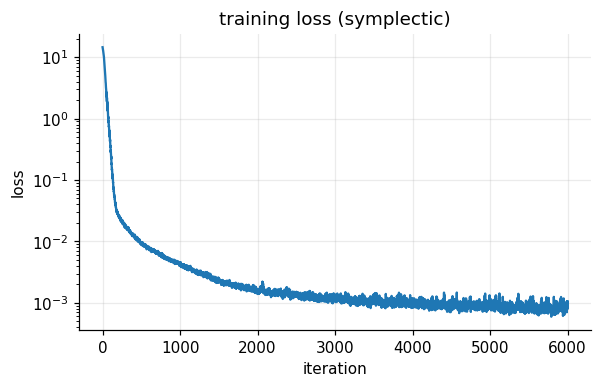

In [7]:
hist = np.array([r["loss"] for r in history])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(hist)
ax.set_xlabel("iteration"); ax.set_ylabel("loss")
ax.set_title(f"training loss ({MODE})")
plt.show()

### Jacobian determinant

The determinant is measured directly, in double precision. For the symplectic
map it is one to machine precision, at any parameters and for the trained model;
for the affine and soft parameterisations it is not.

In [8]:
det_rows = sl.det_statistics(model, problem,
                             torch.linspace(0, problem.t_final, 3, device=device, dtype=dtype),
                             n_points=512)
print(sl.markdown_table(det_rows, columns=["t", "median", "max"]))
det_max = max(r["max"] for r in det_rows)
if MODE == "symplectic":
    assert det_max < 1e-6, det_max
    print(f"\nmax |det - 1| = {det_max:.2e}  (unit Jacobian by construction)")
else:
    print(f"\nmax |det - 1| = {det_max:.2e}")

| t | median | max |
|---|---|---|
| 0 | 0 | 0 |
| 1 | 2.22e-16 | 6.661e-16 |
| 2 | 2.22e-16 | 9.992e-16 |

max |det - 1| = 9.99e-16  (unit Jacobian by construction)


## Reference solution

A spectral semi-Lagrangian solver (Strang splitting, exact FFT sub-steps,
double precision) on an $N^4$ grid.

In [9]:
times = torch.linspace(0, problem.t_final, EVAL_NT, device=device, dtype=dtype)
f_ref, xg, vg = sl.reference_on_grid(problem, times, EVAL_N, EVAL_N,
                                     OUT, device, dtype,
                                     solver_device=SOLVER_DEVICE, verbose=True)
print(xg,vg)

f_mod = sl.evaluate_f_on_grids(f_fn, times, [xg, xg, vg, vg])
print("reference grid:", tuple(f_ref.shape))

solving reference 24x24 on cuda ...
tensor([-6.0000, -5.5000, -5.0000, -4.5000, -4.0000, -3.5000, -3.0000, -2.5000,
        -2.0000, -1.5000, -1.0000, -0.5000,  0.0000,  0.5000,  1.0000,  1.5000,
         2.0000,  2.5000,  3.0000,  3.5000,  4.0000,  4.5000,  5.0000,  5.5000],
       device='cuda:0') tensor([-6.0000, -5.5000, -5.0000, -4.5000, -4.0000, -3.5000, -3.0000, -2.5000,
        -2.0000, -1.5000, -1.0000, -0.5000,  0.0000,  0.5000,  1.0000,  1.5000,
         2.0000,  2.5000,  3.0000,  3.5000,  4.0000,  4.5000,  5.0000,  5.5000],
       device='cuda:0')
reference grid: (5, 24, 24, 24, 24)


## Accuracy vs the reference

Per-time relative $L^2$, $L^\infty$ and RMS error of $f$ on the evaluation grid.

In [10]:
err_rows = sl.error_table(f_mod, f_ref, times)
print(sl.markdown_table(err_rows, columns=["t", "l2", "linf", "rel_l2"]))

| t | l2 | linf | rel_l2 |
|---|---|---|---|
| 0 | 4.475e-10 | 1.49e-08 | 5.141e-08 |
| 0.5 | 0.0001279 | 0.005935 | 0.01469 |
| 1 | 0.000174 | 0.007631 | 0.01999 |
| 1.5 | 0.0002523 | 0.0108 | 0.02899 |
| 2 | 0.0004609 | 0.02525 | 0.05296 |


Phase-space projections at the final time: the charge density $\rho(x,y)$ and
the reduced distribution $f(x, v_x) = \int f\,dy\,dv_y$.

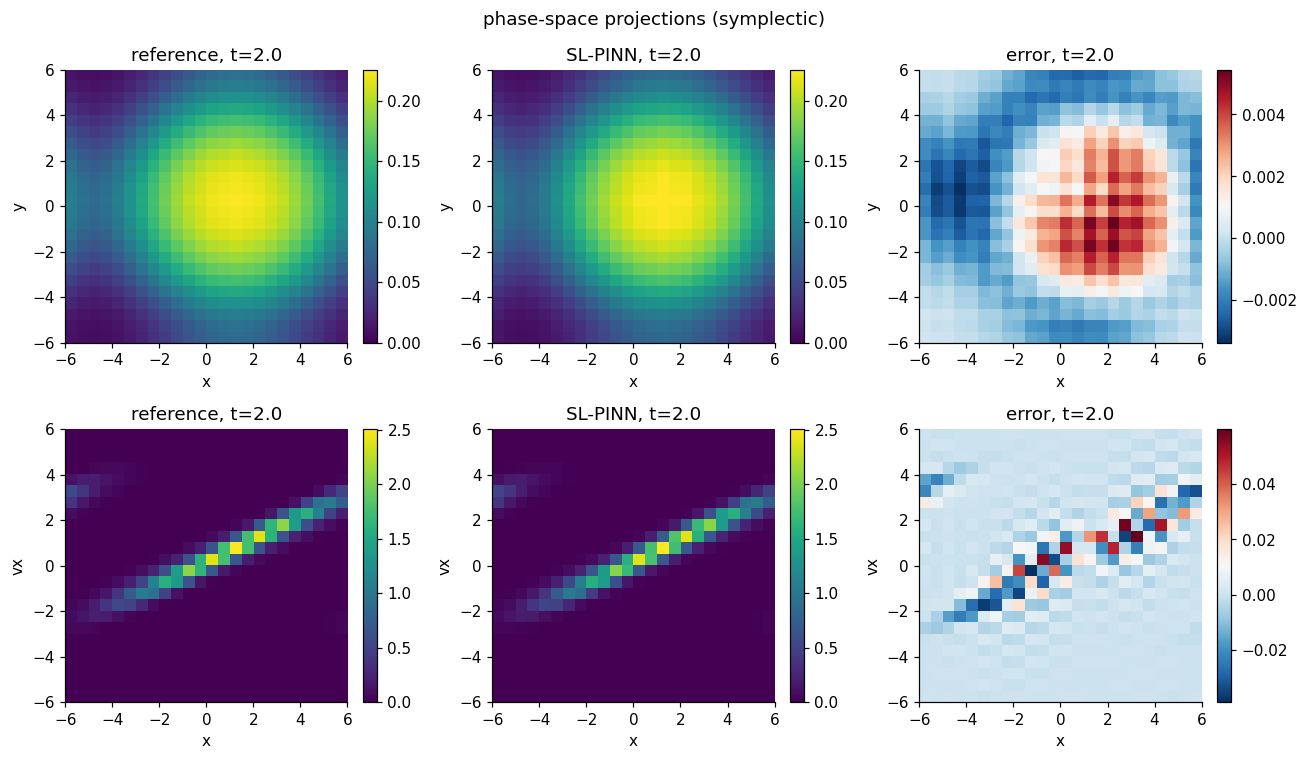

In [11]:
wv = sl.trapezoid_weights(vg)
dx = problem.length / len(xg)
i = len(times) - 1

rho_r = torch.einsum("xyuw,u,w->xy", f_ref[i], wv, wv)
rho_m = torch.einsum("xyuw,u,w->xy", f_mod[i], wv, wv)
red_r = torch.einsum("xyuw,w->xu", f_ref[i], wv) * dx
red_m = torch.einsum("xyuw,w->xu", f_mod[i], wv) * dx

ext_xy = [problem.x_lo, problem.x_hi, problem.x_lo, problem.x_hi]
ext_xv = [problem.x_lo, problem.x_hi, problem.v_lo, problem.v_hi]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for row, (a, b, ext, lab) in enumerate([(rho_r, rho_m, ext_xy, ("x", "y")),
                                        (red_r, red_m, ext_xv, ("x", "vx"))]):
    vmax = float(a.max())
    for ax, (data, title, cmap, kw) in zip(axes[row], [
            (a, "reference", "viridis", dict(vmin=0, vmax=vmax)),
            (b, "SL-PINN", "viridis", dict(vmin=0, vmax=vmax)),
            (b - a, "error", "RdBu_r", dict())]):
        im = ax.imshow(data.T.cpu(), origin="lower", extent=ext, aspect="auto",
                       cmap=cmap, **kw)
        fig.colorbar(im, ax=ax, fraction=0.046)
        ax.set_title(f"{title}, t={float(times[i]):.1f}")
        ax.set_xlabel(lab[0]); ax.set_ylabel(lab[1]); ax.grid(False)
fig.suptitle(f"phase-space projections ({MODE})")
fig.tight_layout()
plt.show()

## Conservation

Mass, momentum, total energy and $E_{\mathrm{rms}}$ over time, and their drift
from the initial value. The metrics for this run are written to
`outputs/<mode>.json`; the table at the end collects every mode that has been
run so far.

In [12]:
nt_c = 11 if QUICK else 21
tc = torch.linspace(0, problem.t_final, nt_c, device=device, dtype=dtype)
fr_c, xc, vc = sl.reference_on_grid(problem, tc, EVAL_N, EVAL_N, OUT, device, dtype,
                                    solver_device=SOLVER_DEVICE)
fm_c = sl.evaluate_f_on_grids(f_fn, tc, [xc, xc, vc, vc])
cons_m = sl.conservation_from_f_grid_2d(fm_c, tc, [xc, xc], [vc, vc],
                                        (problem.length, problem.length), problem.has_field)
cons_r = sl.conservation_from_f_grid_2d(fr_c, tc, [xc, xc], [vc, vc],
                                        (problem.length, problem.length), problem.has_field)

m0 = cons_m.mass[0].abs().clamp_min(1e-30)
e0 = cons_m.energy[0].abs().clamp_min(1e-30)
metrics = {
    "mode": MODE,
    "params": sl.n_params(model),
    "final_rel_l2": err_rows[-1]["rel_l2"],
    "rel_mass_drift": ((cons_m.mass - cons_m.mass[0]).abs().max() / m0).item(),
    "rel_energy_drift": ((cons_m.energy - cons_m.energy[0]).abs().max() / e0).item(),
    "momentum_drift": (cons_m.momentum - cons_m.momentum[0]).abs().max().item(),
    "train_time": train_time,
}
(OUT / f"metrics_2d2v_{MODE}.json").write_text(json.dumps(metrics, indent=1))
print(sl.markdown_table([metrics],
                        columns=["mode", "final_rel_l2", "rel_mass_drift",
                                 "rel_energy_drift", "momentum_drift"]))

| mode | final_rel_l2 | rel_mass_drift | rel_energy_drift | momentum_drift |
|---|---|---|---|---|
| symplectic | 0.05296 | 3.754e-06 | 0.009515 | 0.1225 |


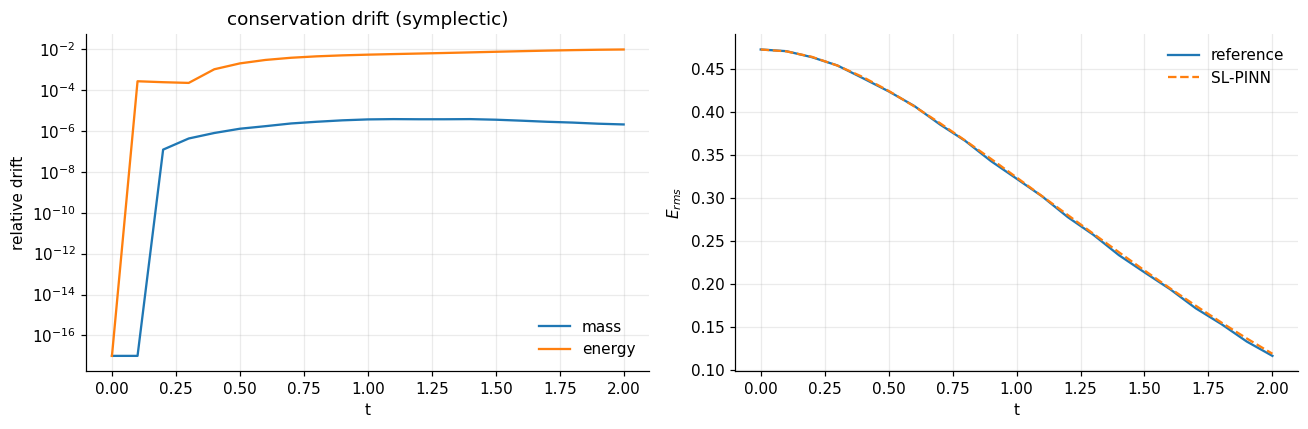

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(tc.cpu(),
                 ((cons_m.mass - cons_m.mass[0]).abs() / m0).clamp_min(1e-17).cpu(),
                 label="mass")
axes[0].semilogy(tc.cpu(),
                 ((cons_m.energy - cons_m.energy[0]).abs() / e0).clamp_min(1e-17).cpu(),
                 label="energy")
axes[0].set_xlabel("t"); axes[0].set_ylabel("relative drift")
axes[0].set_title(f"conservation drift ({MODE})"); axes[0].legend()
axes[1].plot(tc.cpu(), cons_r.e_rms.cpu(), label="reference")
axes[1].plot(tc.cpu(), cons_m.e_rms.cpu(), "--", label="SL-PINN")
axes[1].set_xlabel("t"); axes[1].set_ylabel(r"$E_{rms}$"); axes[1].legend()
fig.tight_layout()
plt.show()

Comparison across the modes that have been run. Because its Jacobian is exactly
one, the symplectic map conserves mass to the quadrature accuracy of the grid —
several orders of magnitude below the soft penalty, which leaves it free to
drift. The affine map conserves mass through the change-of-variables reweighting
(exact in the continuum for a map of the domain onto itself). Momentum and
energy are not fixed by any of these constructions and track the solution
accuracy.

In [ ]:
runs = [json.loads(p.read_text()) for p in sorted(OUT.glob("metrics_2d2v_*.json"))]
print(sl.markdown_table(runs, columns=["mode", "params", "final_rel_l2",
                                       "rel_mass_drift", "rel_energy_drift",
                                       "momentum_drift"]))
if len(runs) < 3:
    missing = {"symplectic", "normalizing", "soft"} - {r["mode"] for r in runs}
    print(f"\nrun the notebook with MODE in {sorted(missing)} to complete the table.")

| mode | params | final_rel_l2 | rel_mass_drift | rel_energy_drift | momentum_drift |
|---|---|---|---|---|---|
| symplectic | 39968 | 0.05296 | 3.754e-06 | 0.009515 | 0.1225 |

run the notebook with MODE in ['normalizing', 'soft'] to complete the table.


## Runtime

The classical solver at several resolutions against the SL-PINN. The solver is
accurate but its cost grows with the $N^4$ grid; the trained map evaluates at
arbitrary $(t, z)$ in milliseconds and its memory scales with the parameter
count rather than the grid.

In [ ]:
def rel_l2(a, b):
    return ((a - b).pow(2).sum().sqrt() / b.pow(2).sum().sqrt().clamp_min(1e-30)).item()


truth_n = 24 if QUICK else 32
resolutions = [8, 12] if QUICK else [12, 16, 24]
solver_dev = (("cuda" if torch.cuda.is_available() else "cpu")
              if SOLVER_DEVICE == "auto" else SOLVER_DEVICE)

t0 = time.time()
truth = sl.solve_reference(problem, nx=truth_n, nv=truth_n, dt=1 / 64,
                           save_times=[problem.t_final], device=solver_dev)
truth_time = time.time() - t0
f_truth = truth.f[-1]

run_rows = []
for n in resolutions:
    if truth_n % n != 0:
        continue
    t0 = time.time()
    ref_n = sl.solve_reference(problem, nx=n, nv=n, dt=1 / 64,
                               save_times=[problem.t_final], device=solver_dev)
    wall = time.time() - t0
    stride = truth_n // n
    sub = f_truth[::stride, ::stride, ::stride, ::stride]
    run_rows.append({"method": f"solver {n}^4", "wall_s": wall,
                     "dof": n ** 4, "rel_l2": rel_l2(ref_n.f[-1], sub)})

xe = truth.x_grid.to(device, dtype)
ve = truth.v_grid.to(device, dtype)
stride = truth_n // max(resolutions)
xe, ve = xe[::stride], ve[::stride]
tf = torch.tensor([problem.t_final], device=device, dtype=dtype)
if device.type == "cuda":
    torch.cuda.synchronize()
t0 = time.time()
f_pinn = sl.evaluate_f_on_grids(f_fn, tf, [xe, xe, ve, ve])[0]
if device.type == "cuda":
    torch.cuda.synchronize()
infer = time.time() - t0
sub = f_truth[::stride, ::stride, ::stride, ::stride]
run_rows.append({"method": f"SL-PINN ({sl.n_params(model)} params)",
                 "wall_s": infer, "dof": sl.n_params(model),
                 "rel_l2": rel_l2(f_pinn.double().cpu(), sub.double().cpu())})

print(f"reference truth: solver {truth_n}^4 ({truth_time:.1f}s)\n")
print(sl.markdown_table(run_rows, columns=["method", "wall_s", "dof", "rel_l2"]))


pinn = run_rows[-1]
solver_rows = [r for r in run_rows if r["method"].startswith("solver")]
# the cheapest solver run that is at least as accurate as the map
matched = [r for r in solver_rows if r["rel_l2"] <= pinn["rel_l2"]]
best = min(matched, key=lambda r: r["wall_s"]) if matched else None

print()
print(f"  numerical solver : {solver_rows[-1]['wall_s']:8.3f} s per solve"
      f"   rel_L2 = {solver_rows[-1]['rel_l2']:.3e}"
      f"   ({solver_rows[-1]['dof']:,} dof, N^4 grid)")
print(f"  SL-PINN          : {pinn['wall_s']:8.3f} s per evaluation"
      f"   rel_L2 = {pinn['rel_l2']:.3e}"
      f"   ({pinn['dof']:,} params)")
if train_time:
    print(f"                     + {train_time:8.1f} s one-off training"
          f"  (= {train_time / max(pinn['wall_s'], 1e-12):,.0f} evaluations"
          f" before it breaks even)")
if best is not None:
    print(f"  at matched accuracy the solver needs {best['method']}"
          f" at {best['wall_s']:.3f} s"
          f" -> map is {best['wall_s'] / max(pinn['wall_s'], 1e-12):.1f}x faster per query")
else:
    print(f"  no solver resolution tested reaches rel_L2 <= {pinn['rel_l2']:.2e};"
          f" the map is more accurate than every grid run here")
print(f"  memory: solver state {truth_n**4 * 8 / 2**30:.3f} GiB at N={truth_n}"
      f" (grows as N^4)   vs map {pinn['dof'] * 4 / 2**20:.2f} MiB (fixed)")

reference truth: solver 32^4 (0.2s)

| method | wall_s | dof | rel_l2 |
|---|---|---|---|
| solver 16^4 | 0.1654 | 65536 | 0.1548 |
| SL-PINN (39968 params) | 0.116 | 39968 | 0.03792 |

  numerical solver :    0.165 s per solve   rel_L2 = 1.548e-01   (65,536 dof, N^4 grid)
  SL-PINN          :    0.116 s per evaluation   rel_L2 = 3.792e-02   (39,968 params)
                     +   5508.1 s one-off training  (= 47,477 evaluations before it breaks even)
  no solver resolution tested reaches rel_L2 <= 3.79e-02; the map is more accurate than every grid run here
  memory: solver state 0.008 GiB at N=32 (grows as N^4)   vs map 0.15 MiB (fixed)


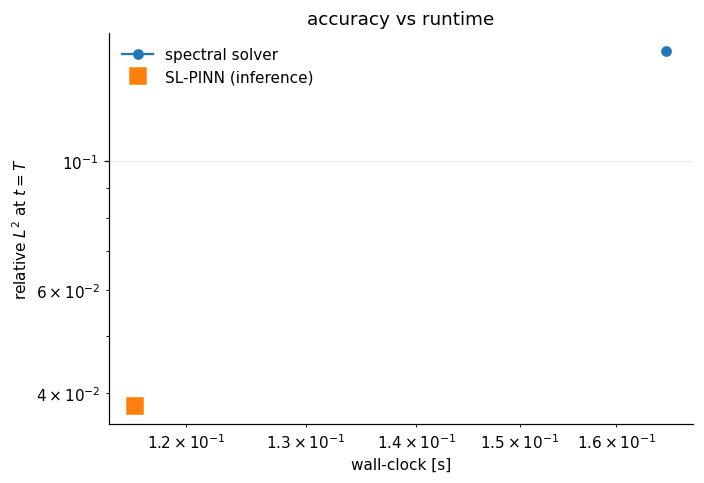

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
solver = [r for r in run_rows if r["method"].startswith("solver")]
pinn = run_rows[-1]
ax.loglog([r["wall_s"] for r in solver], [r["rel_l2"] for r in solver],
          "o-", label="spectral solver")
ax.loglog([pinn["wall_s"]], [pinn["rel_l2"]], "s", markersize=11,
          label="SL-PINN (inference)")
ax.set_xlabel("wall-clock [s]"); ax.set_ylabel(r"relative $L^2$ at $t=T$")
ax.set_title("accuracy vs runtime")
ax.legend()
fig.tight_layout()
plt.show()

## Characteristics

Particle trajectories reconstructed from the learned inverse map, against
trajectories advanced through the reference solver's field. A few phase-space
points are traced from $t=0$ to $t=T$ and projected onto the $(x,y)$ and
$(v_x,v_y)$ planes.

max trajectory deviation over all particles and times: 4.784e-02


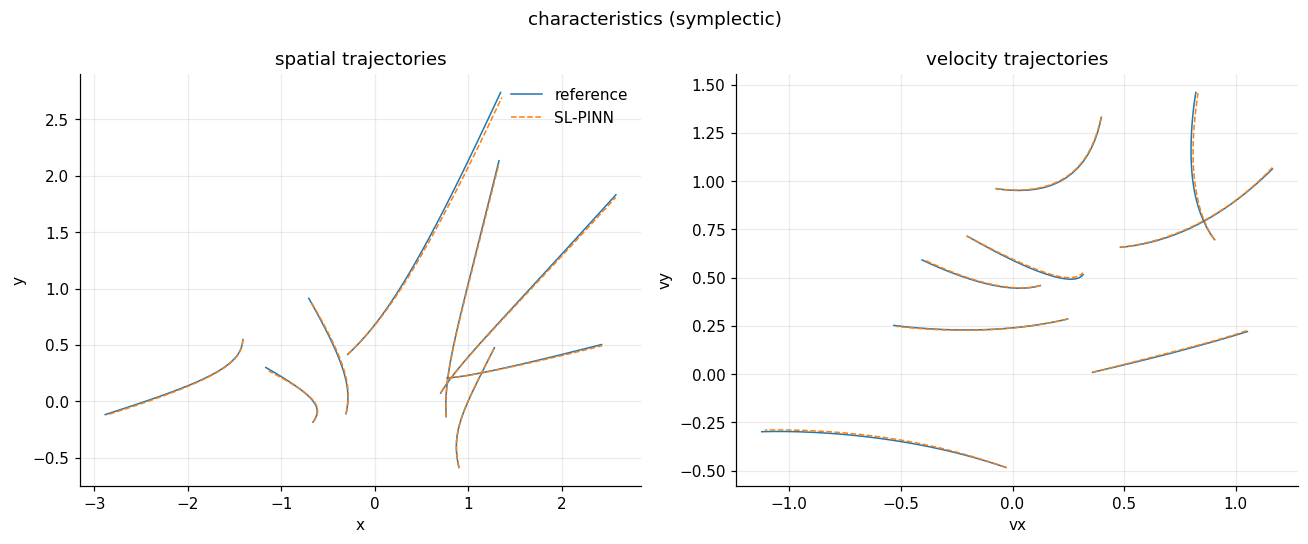

In [17]:
gen = torch.Generator().manual_seed(1)
z0 = torch.stack([
    -1.5 + 3.0 * torch.rand(8, generator=gen),
    -1.5 + 3.0 * torch.rand(8, generator=gen),
    -0.5 + 1.5 * torch.rand(8, generator=gen),
    -0.5 + 1.5 * torch.rand(8, generator=gen),
], dim=-1)

t_ref, traj_ref = sl.characteristics_reference(problem, z0, dt=1 / 64,
                                               nx=EVAL_N, nv=EVAL_N, device=solver_dev)
traj_map = sl.characteristics_map(model, z0, t_ref.to(device))
traj_ref = traj_ref.cpu(); traj_map = traj_map.cpu()

dev_char = (traj_map - traj_ref).norm(dim=-1).max().item()
print(f"max trajectory deviation over all particles and times: {dev_char:.3e}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for j in range(z0.shape[0]):
    ax1.plot(traj_ref[:, j, 0], traj_ref[:, j, 1], "-", color="C0", lw=1,
             label="reference" if j == 0 else None)
    ax1.plot(traj_map[:, j, 0], traj_map[:, j, 1], "--", color="C1", lw=1,
             label="SL-PINN" if j == 0 else None)
    ax2.plot(traj_ref[:, j, 2], traj_ref[:, j, 3], "-", color="C0", lw=1)
    ax2.plot(traj_map[:, j, 2], traj_map[:, j, 3], "--", color="C1", lw=1)
ax1.set_xlabel("x"); ax1.set_ylabel("y"); ax1.set_title("spatial trajectories")
ax2.set_xlabel("vx"); ax2.set_ylabel("vy"); ax2.set_title("velocity trajectories")
ax1.legend()
fig.suptitle(f"characteristics ({MODE})")
fig.tight_layout()
plt.show()